In [1]:
import os
import cv2
import warnings
import itertools
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adamax
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.applications import InceptionResNetV2
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
warnings.filterwarnings('ignore')

# Load Dataset Paths and Labels

In [2]:
# Define the path to the training dataset
data_train = r"D:\Fall 2026 (4)\CS 1st Semester\CS492 Project\Data Set\data"

# Create empty lists to hold image paths and their corresponding labels
filepaths = []
labels = []

# Loop over each label/class directory inside the training path
for label_name in os.listdir(data_train):
    class_folder = os.path.join(data_train, label_name)
    if os.path.isdir(class_folder):  # Ensure it's a folder
        # Loop over each image file in the class directory
        for filename in os.listdir(class_folder):
            image_path = os.path.join(class_folder, filename)
            
            # Append the image path and label to the respective lists
            filepaths.append(image_path)
            labels.append(label_name)

# Combine the file paths and labels into a Pandas DataFrame
data = pd.DataFrame({
    'filepaths': filepaths,
    'labels': labels
})

# Output the DataFrame to verify the data structure
data

,filepaths,labels
0,D:\Fall 2026 (4)\CS 1st Semester\CS492 Project...,Apple___alternaria_leaf_spot
1,D:\Fall 2026 (4)\CS 1st Semester\CS492 Project...,Apple___alternaria_leaf_spot
2,D:\Fall 2026 (4)\CS 1st Semester\CS492 Project...,Apple___alternaria_leaf_spot
3,D:\Fall 2026 (4)\CS 1st Semester\CS492 Project...,Apple___alternaria_leaf_spot
4,D:\Fall 2026 (4)\CS 1st Semester\CS492 Project...,Apple___alternaria_leaf_spot
...,...,...
116142,D:\Fall 2026 (4)\CS 1st Semester\CS492 Project...,Watermelon___mosaic_virus
116143,D:\Fall 2026 (4)\CS 1st Semester\CS492 Project...,Watermelon___mosaic_virus
116144,D:\Fall 2026 (4)\CS 1st Semester\CS492 Project...,Watermelon___mosaic_virus
116145,D:\Fall 2026 (4)\CS 1st Semester\CS492 Project...,Watermelon___mosaic_virus


In [3]:
print(np.unique(labels))

['Apple___alternaria_leaf_spot' 'Apple___black_rot' 'Apple___brown_spot'
 'Apple___gray_spot' 'Apple___healthy' 'Apple___rust' 'Apple___scab'
 'Bell_pepper___bacterial_spot' 'Bell_pepper___healthy'
 'Blueberry___healthy' 'Cassava___bacterial_blight'
 'Cassava___brown_streak_disease' 'Cassava___green_mottle'
 'Cassava___healthy' 'Cassava___mosaic_disease' 'Cherry___healthy'
 'Cherry___powdery_mildew' 'Coffee___healthy' 'Coffee___red_spider_mite'
 'Coffee___rust' 'Corn___common_rust' 'Corn___gray_leaf_spot'
 'Corn___healthy' 'Corn___northern_leaf_blight' 'Grape___Leaf_blight'
 'Grape___black_measles' 'Grape___black_rot' 'Grape___healthy'
 'Orange___citrus_greening' 'Peach___bacterial_spot' 'Peach___healthy'
 'Potato___bacterial_wilt' 'Potato___early_blight' 'Potato___healthy'
 'Potato___late_blight' 'Potato___leafroll_virus' 'Potato___mosaic_virus'
 'Potato___nematode' 'Potato___pests' 'Potato___phytophthora'
 'Raspberry___healthy' 'Rice___bacterial_blight' 'Rice___blast'
 'Rice___brown_

# Plot Images per Category

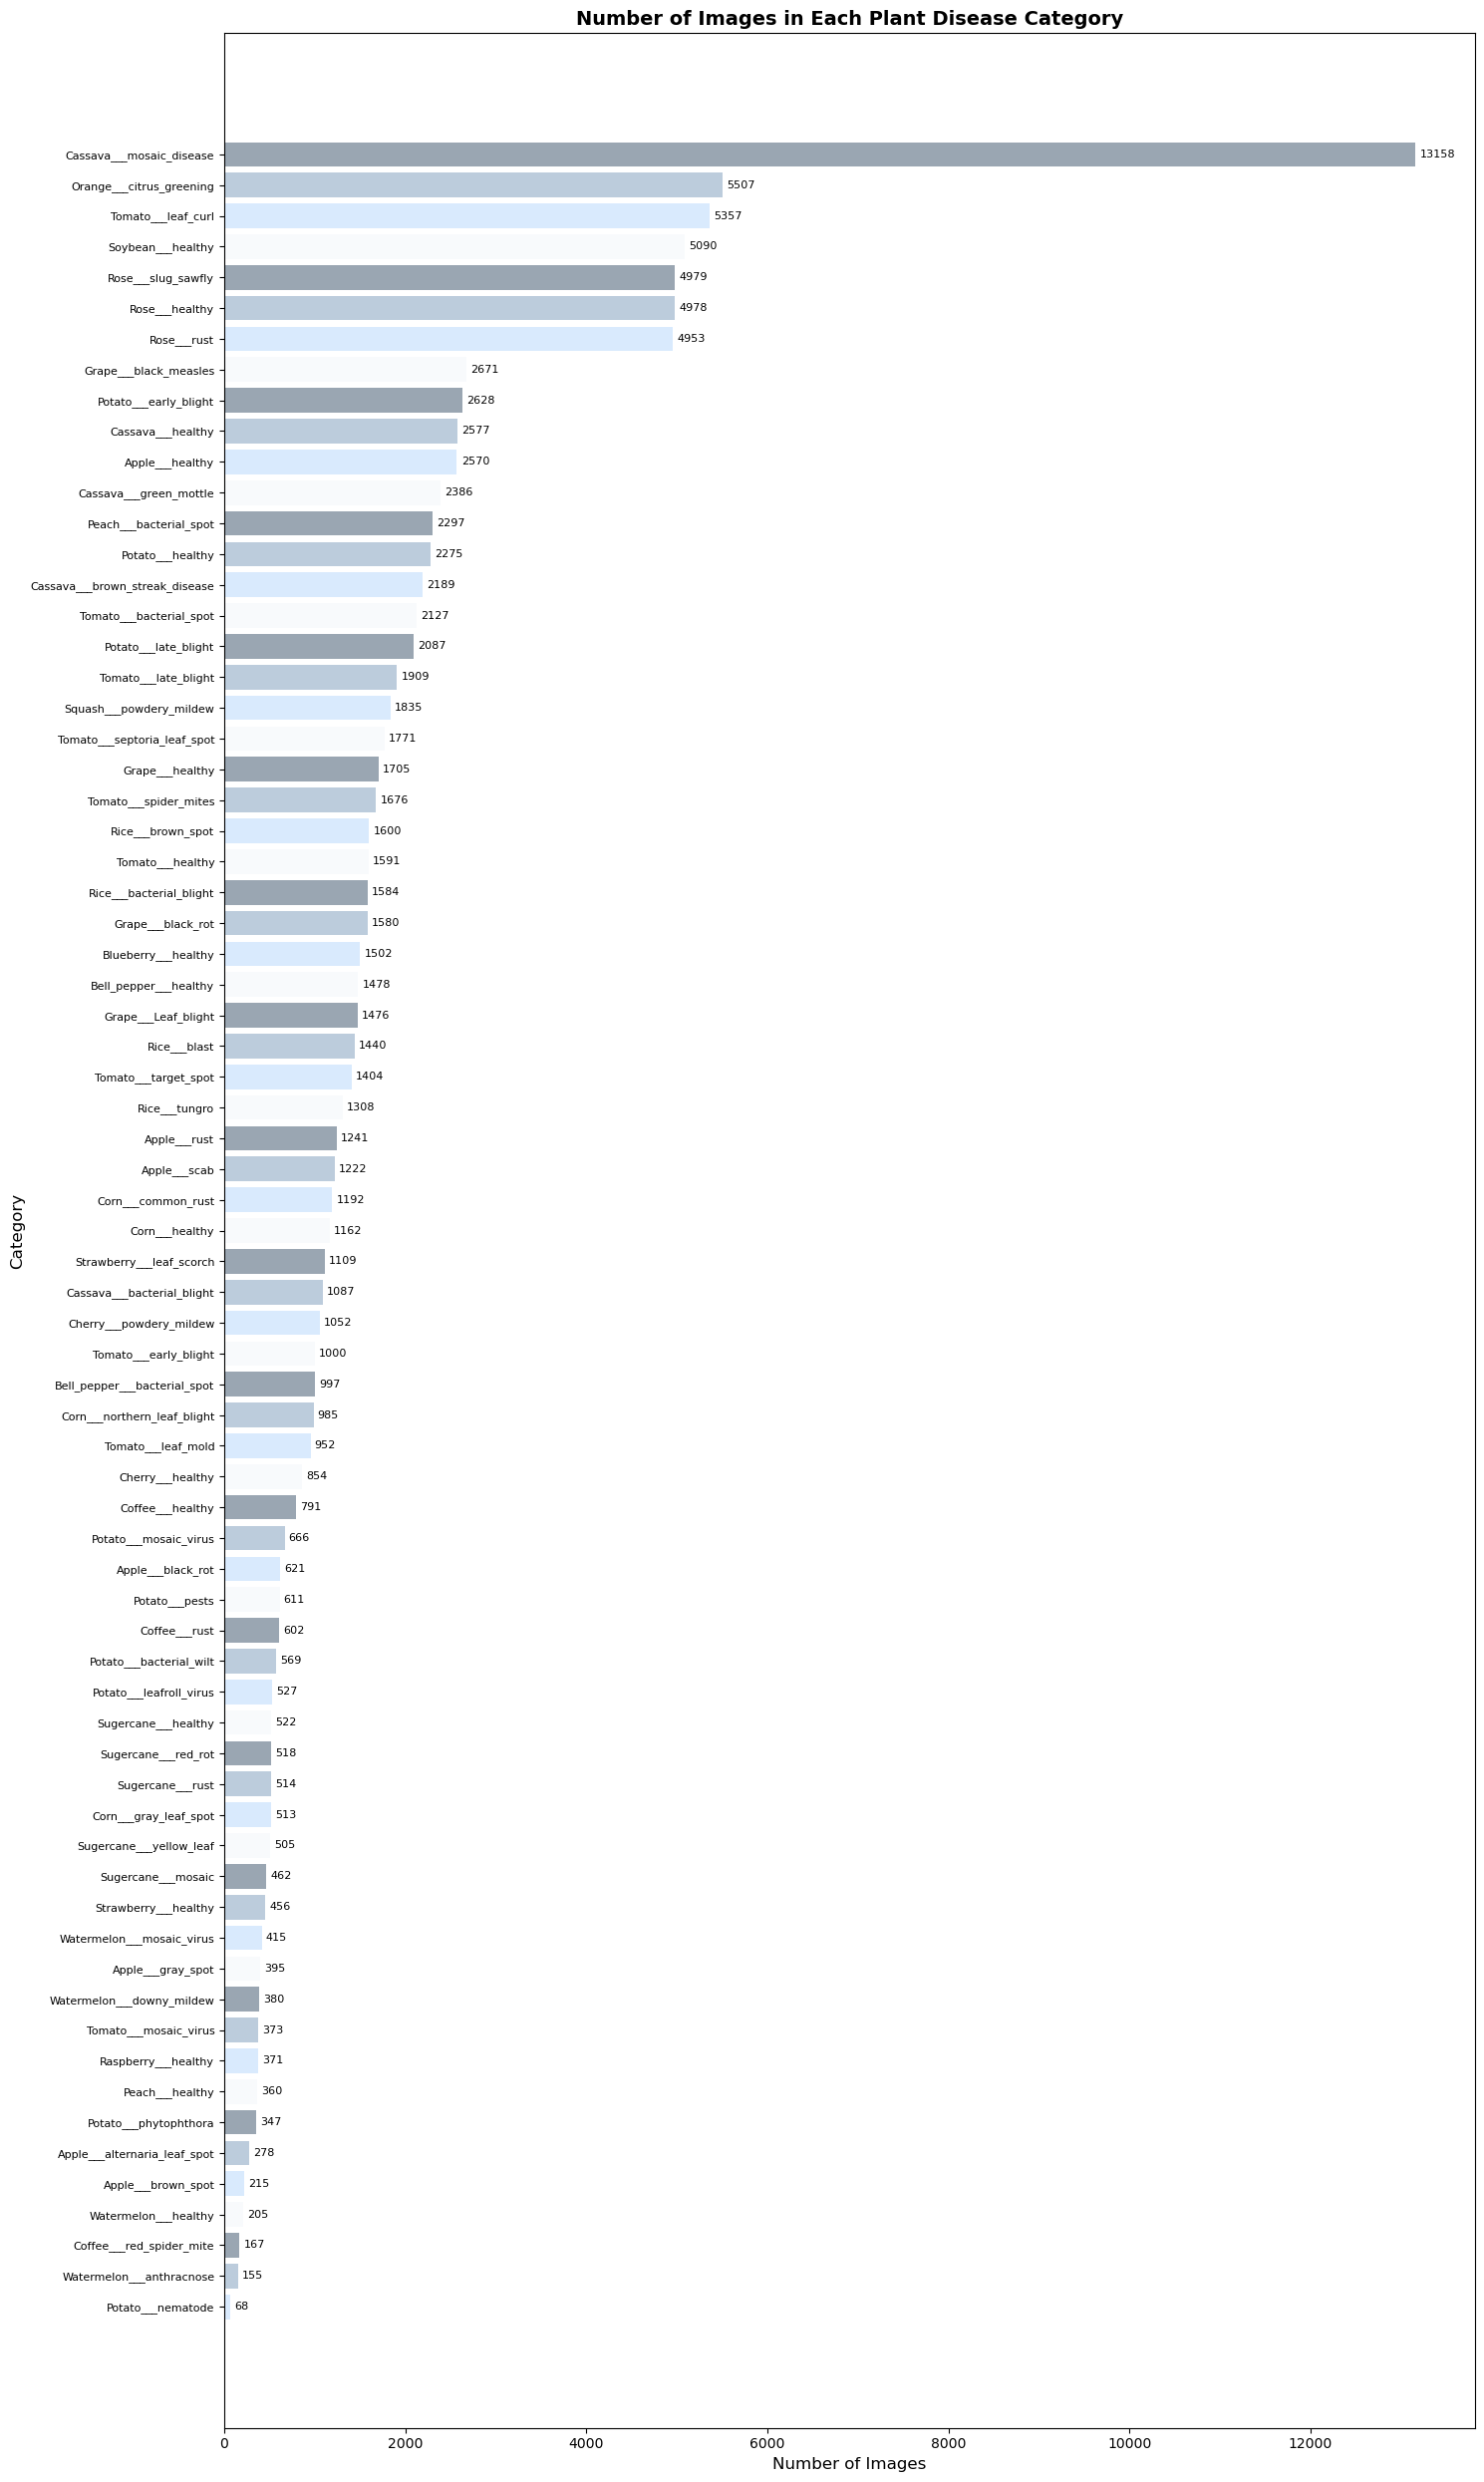

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

colors = ['#9AA6B2', '#BCCCDC', '#D9EAFD', '#F8FAFC']

label_counts = data['labels'].value_counts()

fig, ax = plt.subplots(figsize=(15, 25))  
bars = ax.barh(label_counts.index, label_counts.values, color=colors * (len(label_counts) // len(colors) + 1))

ax.bar_label(bars, fmt='%d', padding=3, fontsize=8)

ax.set_title('Number of Images in Each Plant Disease Category', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Images', fontsize=12)
ax.set_ylabel('Category', fontsize=12)

ax.invert_yaxis()

plt.yticks(fontsize=8)
plt.xticks(fontsize=10)

plt.tight_layout()
plt.show()

# Split Dataset into Train, Valid and Test

In [5]:
train_df, temp_df = train_test_split(data, test_size=0.2, random_state=42, stratify=data['labels'])

In [6]:
valid_df, test_df = train_test_split(temp_df, test_size=0.2, random_state=42, stratify=temp_df['labels'])

In [7]:
print("Train size:", len(train_df))
print("Validation size:", len(valid_df))
print("Test size:", len(test_df))

Train size: 92917
Validation size: 18584
Test size: 4646


# Compute Class Weights for Imbalanced Dataset

In [8]:
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(data['labels']),
    y=data['labels']
)
class_weights_dict = dict(zip(np.unique(data['labels']), class_weights))
print("Class Weights:", class_weights_dict)

Class Weights: {'Apple___alternaria_leaf_spot': 5.884436113081366, 'Apple___black_rot': 2.634256424213558, 'Apple___brown_spot': 7.6087127415656735, 'Apple___gray_spot': 4.14145123908005, 'Apple___healthy': 0.6365265523099688, 'Apple___rust': 1.318189556355052, 'Apple___scab': 1.3386851386551717, 'Bell_pepper___bacterial_spot': 1.6407956263155665, 'Bell_pepper___healthy': 1.1068154529341134, 'Blueberry___healthy': 1.089129986309334, 'Cassava___bacterial_blight': 1.504943182554388, 'Cassava___brown_streak_disease': 0.747315321807501, 'Cassava___green_mottle': 0.6856132604512237, 'Cassava___healthy': 0.634797531795351, 'Cassava___mosaic_disease': 0.12432537159421035, 'Cherry___healthy': 1.9155424349374939, 'Cherry___powdery_mildew': 1.5550125850157983, 'Coffee___healthy': 2.0681077616139314, 'Coffee___red_spider_mite': 9.79564814033904, 'Coffee___rust': 2.717397407702026, 'Corn___common_rust': 1.3723768787219963, 'Corn___gray_leaf_spot': 3.1888367240479916, 'Corn___healthy': 1.4078082955

# Data Augmentation and Image Data Generators

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Train data augmentation
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    channel_shift_range=30.0,
    fill_mode='nearest'
)

valid_datagen = ImageDataGenerator(rescale=1.0 / 255)
test_datagen  = ImageDataGenerator(rescale=1.0 / 255)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    batch_size=32,
    color_mode='rgb',
    class_mode='categorical',
    shuffle=True
)

validation_generator = valid_datagen.flow_from_dataframe(
    valid_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    batch_size=32,
    color_mode='rgb',
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    batch_size=32,
    color_mode='rgb',
    class_mode='categorical',
    shuffle=False

)

Found 92917 validated image filenames belonging to 71 classes.
Found 18584 validated image filenames belonging to 71 classes.
Found 4646 validated image filenames belonging to 71 classes.


# Load Pretrained MobileNetV2 and Freeze Base Layers

In [10]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

for layer in base_model.layers:
    layer.trainable = False

# Build and Compile the CNN Model (feature extractor)

In [13]:
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),        
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(71, activation='softmax')  
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 71)             │        18,247 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,604,167 (9.93 MB)

 Trainable params: 346,183 (1.32 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

# Early stopping after 10 epochs without improvement in validation loss

In [14]:
# Set up EarlyStopping to monitor validation loss
early_stopping = EarlyStopping(
    monitor='val_loss',             # Stop training when validation loss stops improving
    patience=10,                     # Wait for 10 epochs before stopping
    restore_best_weights=True       # Roll back to the best weights observed during training
)

# Save only the best performing model based on validation accuracy

In [15]:
checkpoint = ModelCheckpoint(
    filepath='best_model.keras', # Save model in Keras format
    monitor='val_accuracy',          # Monitor validation accuracy
    save_best_only=True,             # Save only when the model improves
    mode='max',                      # Higher accuracy is better
    save_weights_only=False,         # Save full model (not just weights)
    verbose=1                        # Output message when model is saved
)

# Reduce learning rate if validation loss plateaus for 10 epochs

In [16]:
# Reduce learning rate when the validation loss stops improving
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',     # Monitor validation loss
    factor=0.1,             # Reduce LR by 10x when triggered
    patience=10,             # Number of epochs with no improvement before reduction
    verbose=1               # Log the LR change
)

# Train the model with callbacks for early stopping, checkpointing, and learning rate scheduling

In [17]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=50,  
    callbacks=[
        early_stopping,
        checkpoint,
        reduce_lr
    ],
    class_weight=class_weights_dict,
    verbose=1
)

Epoch 1/50
2904/2904 ━━━━━━━━━━━━━━━━━━━━ 0s 589ms/step - accuracy: 0.6696 - loss: 1.1959
Epoch 1: val_accuracy improved from -inf to 0.84142, saving model to best_model.keras
2904/2904 ━━━━━━━━━━━━━━━━━━━━ 1902s 654ms/step - accuracy: 0.6696 - loss: 1.1958 - val_accuracy: 0.8414 - val_loss: 0.4491 - learning_rate: 0.0010
Epoch 2/50
2904/2904 ━━━━━━━━━━━━━━━━━━━━ 0s 520ms/step - accuracy: 0.8127 - loss: 0.5659
Epoch 2: val_accuracy improved from 0.84142 to 0.85719, saving model to best_model.keras
2904/2904 ━━━━━━━━━━━━━━━━━━━━ 1687s 581ms/step - accuracy: 0.8127 - loss: 0.5659 - val_accuracy: 0.8572 - val_loss: 0.4192 - learning_rate: 0.0010
Epoch 3/50
2904/2904 ━━━━━━━━━━━━━━━━━━━━ 0s 515ms/step - accuracy: 0.8307 - loss: 0.5044
Epoch 3: val_accuracy improved from 0.85719 to 0.86908, saving model to best_model.keras
2904/2904 ━━━━━━━━━━━━━━━━━━━━ 1670s 575ms/step - accuracy: 0.8307 - loss: 0.5044 - val_accuracy: 0.8691 - val_loss: 0.3762 - learning_rate: 0.0010
Epoch 4/50
2904/2904 ━

# plot_training_curves

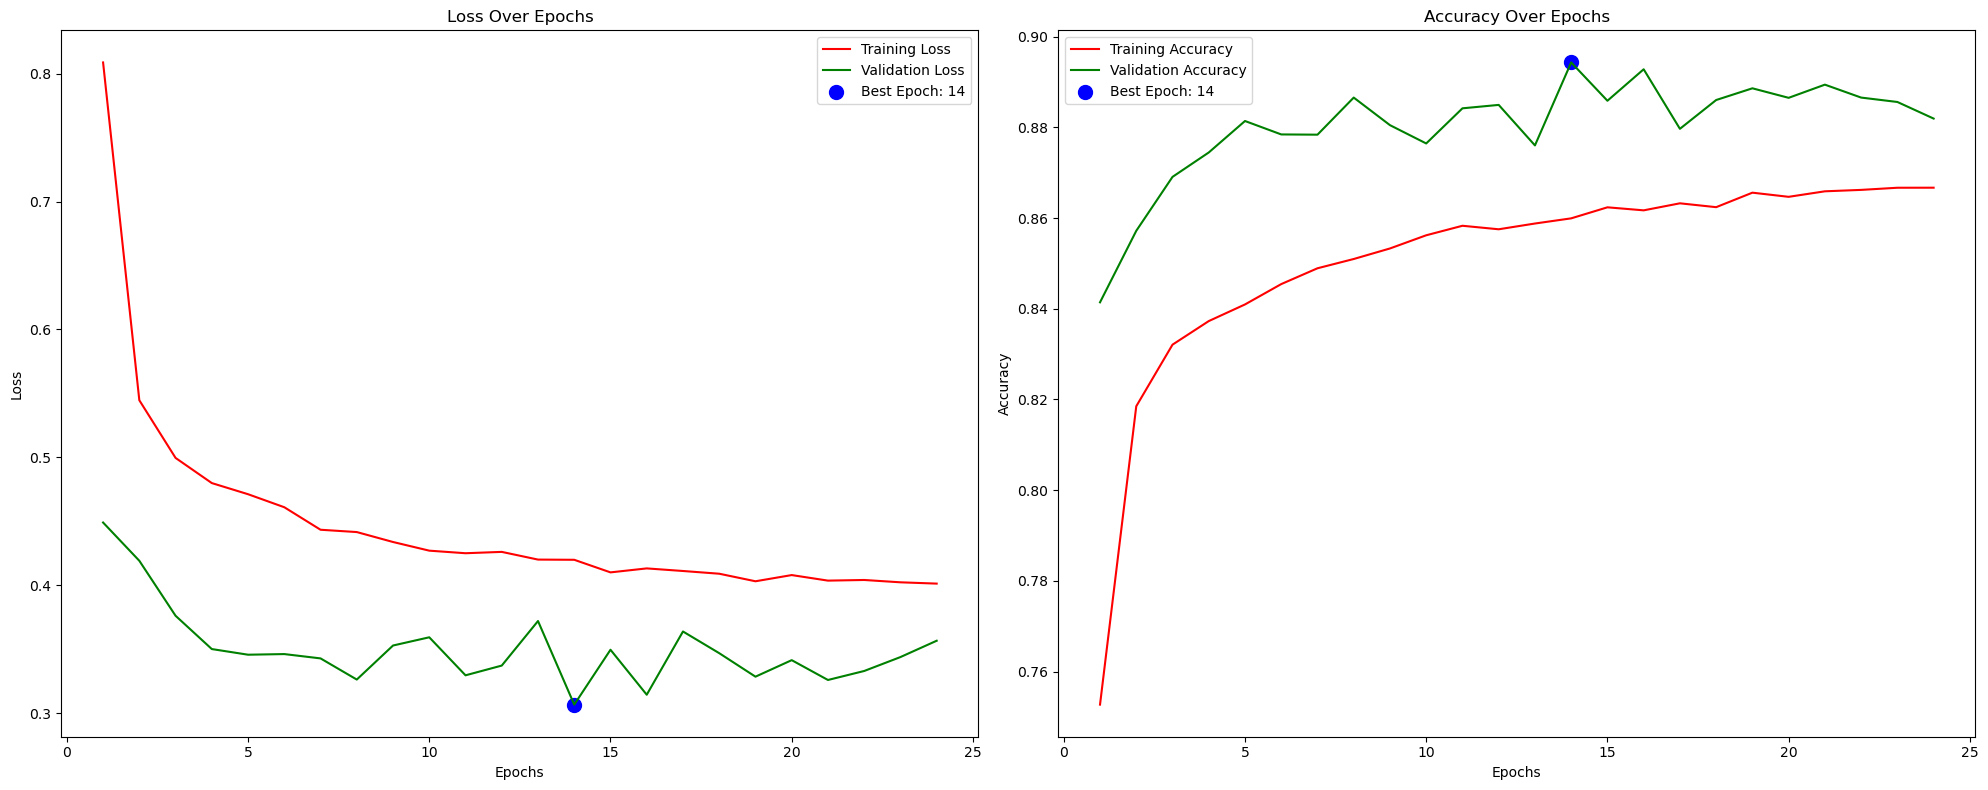

In [18]:
# Extract metrics from training history
tr_acc = history.history['accuracy']         # Training accuracy
val_acc = history.history['val_accuracy']    # Validation accuracy
tr_loss = history.history['loss']            # Training loss
val_loss = history.history['val_loss']       # Validation loss
epochs = [i + 1 for i in range(len(tr_acc))] # Epoch range for plotting

# Create subplots: loss and accuracy
plt.figure(figsize=(20, 8))

# Plot training and validation loss
plt.subplot(1, 2, 1)
plt.plot(epochs, tr_loss, 'r', label='Training Loss')
plt.plot(epochs, val_loss, 'g', label='Validation Loss')
plt.scatter(np.argmin(val_loss) + 1, min(val_loss), s=100, c='blue',
            label=f'Best Epoch: {np.argmin(val_loss) + 1}')
plt.title("Loss Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, tr_acc, 'r', label='Training Accuracy')
plt.plot(epochs, val_acc, 'g', label='Validation Accuracy')
plt.scatter(np.argmax(val_acc) + 1, max(val_acc), s=100, c='blue',
            label=f'Best Epoch: {np.argmax(val_acc) + 1}')
plt.title("Accuracy Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Adjust layout and show the plots
plt.tight_layout()
plt.show()

# evaluate_model

In [19]:
# Evaluate the model on the training dataset
train_score = model.evaluate(train_generator)

# Evaluate the model on the validation dataset
valid_score = model.evaluate(validation_generator)

# Evaluate the model on the external test dataset (friends' dataset)
test_score = model.evaluate(test_generator)

# Print the evaluation results with formatting
print("=== Training Performance ===")
print(f"Train Loss: {train_score[0]:.4f}")
print(f"Train Accuracy: {train_score[1]*100:.2f}%")
print('-' * 30)

print("=== Validation Performance ===")
print(f"Validation Loss: {valid_score[0]:.4f}")
print(f"Validation Accuracy: {valid_score[1]*100:.2f}%")
print('-' * 30)

print("=== Test Performance ===")
print(f"Test Loss: {test_score[0]:.4f}")
print(f"Test Accuracy: {test_score[1]*100:.2f}%")

2904/2904 ━━━━━━━━━━━━━━━━━━━━ 1540s 530ms/step - accuracy: 0.8926 - loss: 0.3013
581/581 ━━━━━━━━━━━━━━━━━━━━ 186s 321ms/step - accuracy: 0.9000 - loss: 0.2986
146/146 ━━━━━━━━━━━━━━━━━━━━ 48s 331ms/step - accuracy: 0.8957 - loss: 0.3122
=== Training Performance ===
Train Loss: 0.3015
Train Accuracy: 89.24%
------------------------------
=== Validation Performance ===
Validation Loss: 0.3068
Validation Accuracy: 89.43%
------------------------------
=== Test Performance ===
Test Loss: 0.3053
Test Accuracy: 89.58%


# Confusion Matrix & Classification Report

=== Classification Report ===
                                precision    recall  f1-score   support

  Apple___alternaria_leaf_spot       1.00      0.64      0.78        11
             Apple___black_rot       1.00      0.96      0.98        25
            Apple___brown_spot       1.00      1.00      1.00         9
             Apple___gray_spot       0.69      0.69      0.69        16
               Apple___healthy       0.85      0.96      0.90       103
                  Apple___rust       0.82      0.94      0.88        50
                  Apple___scab       0.92      0.73      0.82        49
  Bell_pepper___bacterial_spot       0.97      0.95      0.96        40
         Bell_pepper___healthy       0.95      0.98      0.97        59
           Blueberry___healthy       1.00      1.00      1.00        60
    Cassava___bacterial_blight       0.51      0.56      0.53        43
Cassava___brown_streak_disease       0.63      0.35      0.45        88
        Cassava___green_mottle   

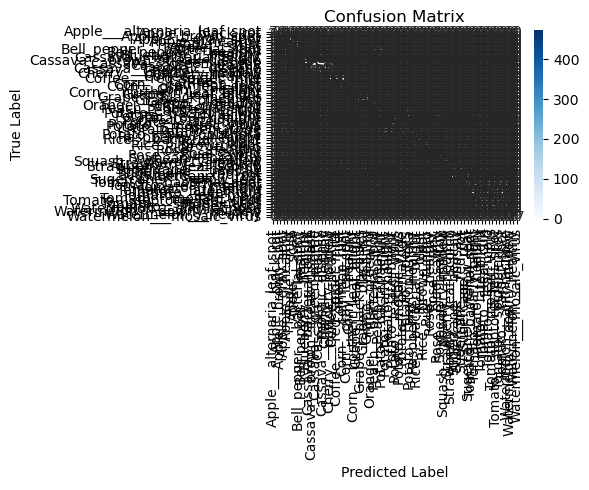

In [20]:
# Get true labels and predictions from the test generator
Y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

# Predict probabilities
Y_pred_probs = model.predict(test_generator, verbose=0)
Y_pred = np.argmax(Y_pred_probs, axis=1)

# Generate classification report
print("=== Classification Report ===")
print(classification_report(Y_true, Y_pred, target_names=class_names))

# Generate confusion matrix
cm = confusion_matrix(Y_true, Y_pred)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

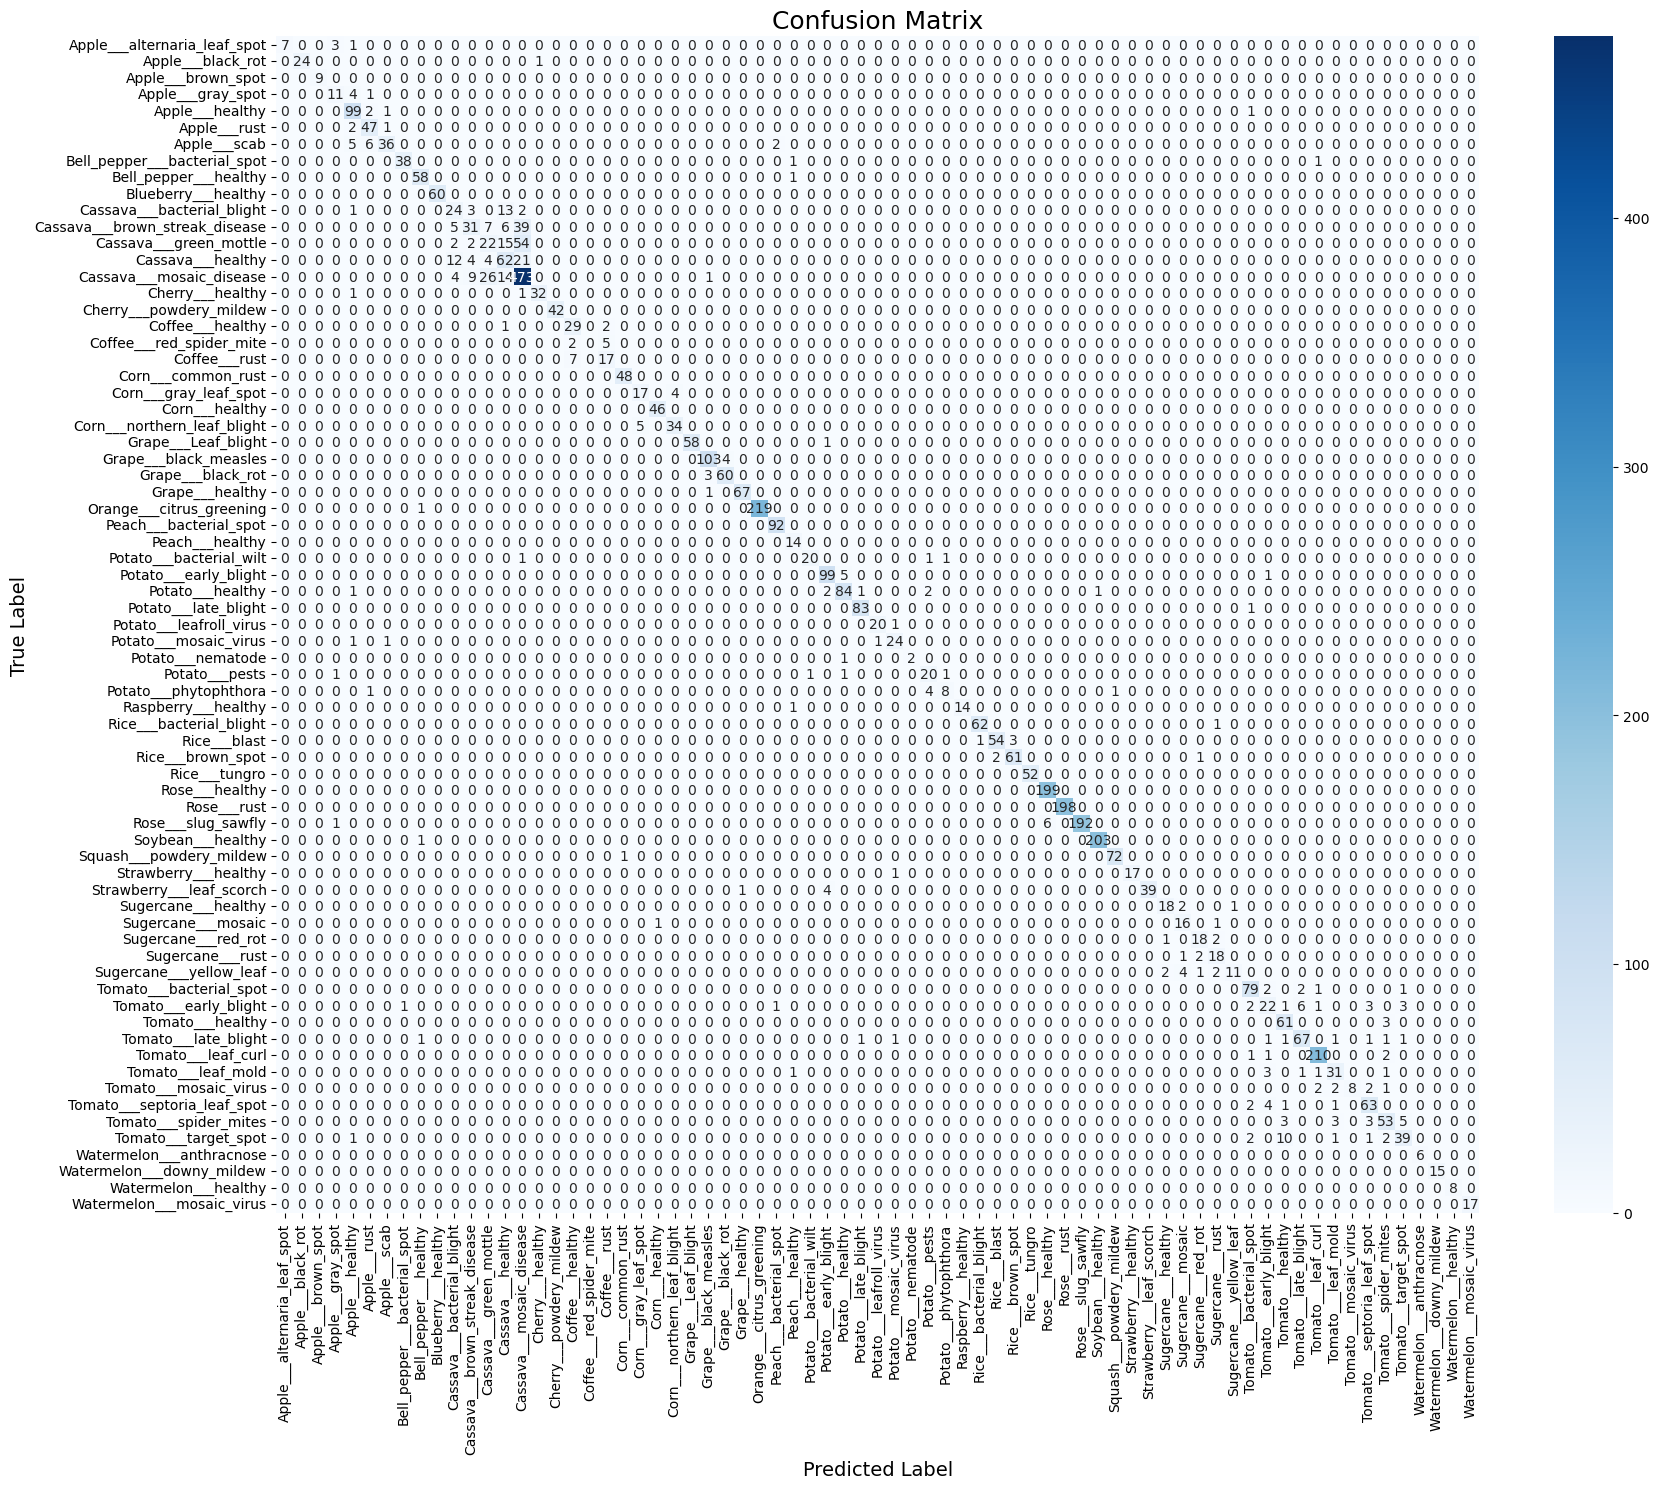

In [21]:
plt.figure(figsize=(18, 15)) 
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 10}  
)
plt.title('Confusion Matrix', fontsize=18)
plt.xlabel('Predicted Label', fontsize=14)
plt.ylabel('True Label', fontsize=14)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()
